# 05 · Economy-mood variant: does talk about inflation, rates and the Fed predict gold?

Gold is a safe-haven asset, so economy worries may move it. This notebook tests posts about
**inflation, interest rates, the Fed, yields and recession** from r/economy, r/Economics,
r/wallstreetbets, r/stocks and r/CanadianInvestor, over the same frozen window.

* Posts: `data/clean/macro_posts.parquet`, built by `python -m collector.macro_backfill` (same removal,
  language and de-duplication rules as the gold data; keyword list fixed in advance).
* Scorer: FinBERT used as is. Here positive / negative = **good / bad news for the economy**.
* Features: `python -m processing.macro features`, which joins hourly economy features onto the main
  `features.parquet`, so the target and test hours are unchanged.
* **The model learns the direction.** Bad-economy talk can mean gold up (panic, inflation) or down
  (rate hikes, high yields). We don't hard-code either; the coefficients show what was learned.

**Supervised learning only.** Two new models: **5** logistic regression and **6** depth-3 tree, both on
price + economy features, against the same majority-class and price-only baselines.

### Success criteria, fixed before any labels or results were seen
The economy variant becomes the headline result **only if all three hold**:
1. **Labellers agree with each other:** Cohen's κ ≥ 0.40 on the 15 posts labelled twice.
2. **FinBERT passes validation:** agreement above always guessing the most common human label,
   *and* balanced score (mean agreement per human class) ≥ 0.50 (chance = 0.33).
3. **A model beats price-only by more than luck:** exact McNemar p < 0.005 (Bonferroni: 10 sentiment
   models tried in the project) on the 124 test hours, *and* it is robust. The tree must beat price-only
   in ≥ 7 of 9 cells (depth 2/3/4 × split Sept 26/28/30). The logistic model has no depth, so it must
   beat price-only at all 3 split dates.

In [1]:
import os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

FIGURES = Path("reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
WINDOW = ("2026-09-08", "2026-10-05T16:00")  # frozen collection window (handoff §2)

from processing.features import PRICE_FEATURES, SENTIMENT_FEATURES
from processing.macro import MACRO_FEATURES

base = pd.read_parquet("data/clean/features.parquet")
features = pd.read_parquet("data/clean/features_macro.parquet")
pd.testing.assert_frame_equal(features[base.columns], base)   # main table carried over unchanged
macro_posts = pd.read_parquet("data/clean/macro_posts.parquet")
print(f"{len(macro_posts)} de-duplicated economy posts; {int(features['macro_had_posts'].sum())} of "
      f"{len(features)} hours have at least one ({features['macro_had_posts'].mean():.0%})")

573 de-duplicated economy posts; 329 of 664 hours have at least one (50%)


## 1. What the keyword filter kept

In [2]:
print(pd.crosstab(macro_posts["subreddit"], macro_posts["finbert_label"], margins=True).to_string())
print("\nRandom examples (by eye: is it economy talk?):")
if "text" in macro_posts:
    for _, r in macro_posts.sample(10, random_state=0).iterrows():
        print(f"  [{r['subreddit']}] {r['text'][:110]}")
else:  # the published table keeps only a hash of each post's text
    print("  (post text is not published; data/validation/macro_sample.csv has 45 examples with text)")

finbert_label     bad  good  neutral  All
subreddit                                
CanadianInvestor    5     1        2    8
Economics          25    33       27   85
economy           116    52      123  291
stocks             23     9       34   66
wallstreetbets     35     9       79  123
All               204   104      265  573

Random examples (by eye: is it economy talk?):
  (post text is not published; data/validation/macro_sample.csv has 45 examples with text)


## 2. Validation: do people agree with each other, and with FinBERT?
`data/validation/macro_sample.csv` (45 posts, 15 per FinBERT class, labelled blind with no scorer
column; rule in `data/validation/MACRO_LABELLING.md`) and `macro_overlap.csv` (its first 15 posts,
labelled a second time by a different person).

In [3]:
from sklearn.metrics import cohen_kappa_score, confusion_matrix

LABELS = ["bad", "neutral", "good"]
def read_labels(path):
    d = pd.read_csv(path, encoding="utf-8", keep_default_na=False)
    d["human_label"] = d["human_label"].str.strip().str.lower()
    return d

sample, overlap = read_labels("data/validation/macro_sample.csv"), read_labels("data/validation/macro_overlap.csv")
labelled = sample["human_label"].isin(LABELS).all() and overlap["human_label"].isin(LABELS).all()
kappa = agree_f = yard = balanced = None
if not labelled:
    print(f"Awaiting labels: {sample['human_label'].isin(LABELS).sum()}/45 in the sample, "
          f"{overlap['human_label'].isin(LABELS).sum()}/15 in the overlap file.")
else:
    pair = sample.merge(overlap, on="post_id", suffixes=("_1", "_2"), validate="1:1")
    kappa = cohen_kappa_score(pair["human_label_1"], pair["human_label_2"])
    print(f"Labeller agreement on {len(pair)} double-labelled posts: {(pair['human_label_1'] == pair['human_label_2']).mean():.0%} "
          f"identical, Cohen's kappa = {kappa:.2f}  ({', '.join(sorted(set(pair['labelled_by_1']) | set(pair['labelled_by_2'])))})")
    both = sample.merge(macro_posts[["post_id", "finbert_score", "finbert_label"]], on="post_id", validate="1:1")
    ok = both["human_label"] == both["finbert_label"]
    agree_f = ok.mean()
    majority = both["human_label"].value_counts()
    yard = majority.iloc[0] / len(both)
    balanced = ok.groupby(both["human_label"]).mean().mean()
    print(f"FinBERT vs human labels: agreement {agree_f:.1%} ({ok.sum()}/{len(both)}), balanced {balanced:.2f}")
    print(f"Yardstick, always '{majority.index[0]}': agreement {yard:.1%}, balanced {1 / both['human_label'].nunique():.2f}")
    print("Agreement by human label:", ok.groupby(both["human_label"]).mean().round(2).to_dict())
    display(pd.DataFrame(confusion_matrix(both["human_label"], both["finbert_label"], labels=LABELS),
                         index=[f"human {l}" for l in LABELS], columns=[f"FinBERT {l}" for l in LABELS]))
    print("FinBERT disagreements:")
    display(both[~ok][["subreddit", "finbert_score", "finbert_label", "human_label", "text"]])

Awaiting labels: 0/45 in the sample, 0/15 in the overlap file.


## 3. Economy mood vs. gold price

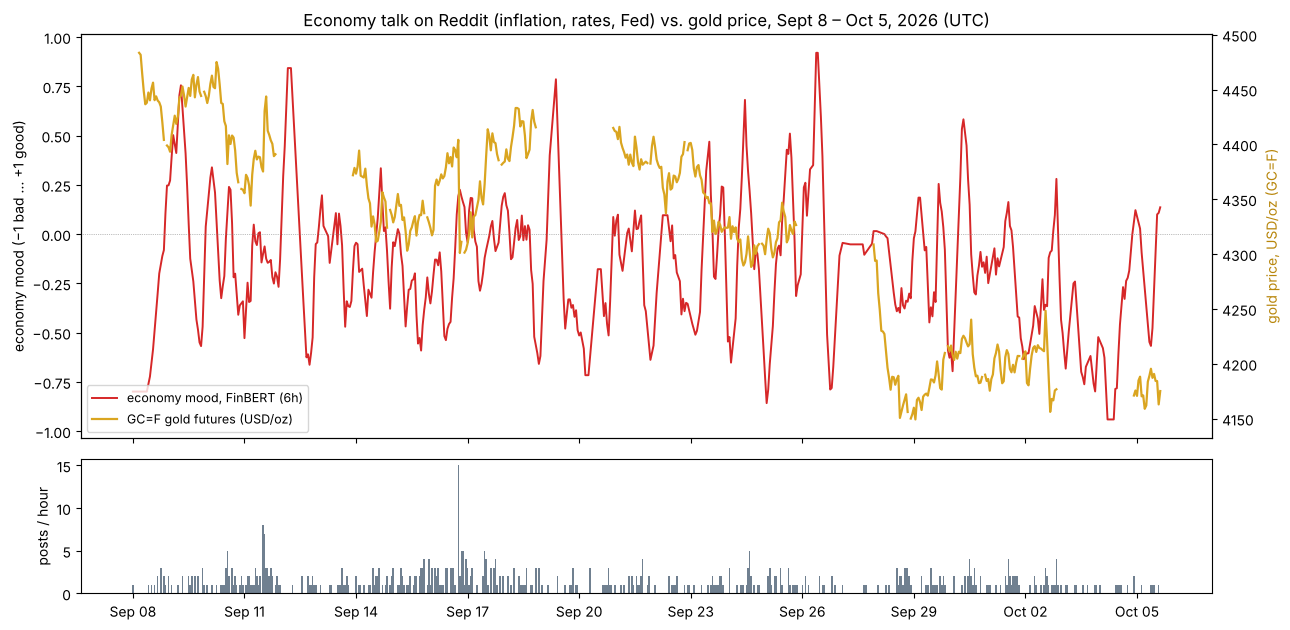

In [4]:
import matplotlib.dates as mdates
fig, (ax1, ax3) = plt.subplots(2, 1, figsize=(13, 6.4), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax1.plot(features.index, features["macro_mood_roll_mean_6h"], color="tab:red", lw=1.4, label="economy mood, FinBERT (6h)")
ax1.axhline(0, color="gray", lw=0.5, ls=":")
ax1.set_ylabel("economy mood (−1 bad … +1 good)")
ax2 = ax1.twinx()
ax2.plot(features.index, features["xau_usd"], color="goldenrod", lw=1.6, label="GC=F gold futures (USD/oz)")
ax2.set_ylabel("gold price, USD/oz (GC=F)", color="darkgoldenrod")
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax1.legend(lines, [l.get_label() for l in lines], loc="lower left", fontsize=9)
ax1.set_title("Economy talk on Reddit (inflation, rates, Fed) vs. gold price, Sept 8 – Oct 5, 2026 (UTC)")
ax3.bar(features.index, features["macro_post_count"], width=1 / 24, color="slategray")
ax3.set_ylabel("posts / hour")
ax3.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
fig.tight_layout()
fig.savefig(FIGURES / "eda_5_economy_mood_vs_price.png", dpi=150, bbox_inches="tight")

## 4. Models: price-only vs. price + economy features
Same split as `04_model.ipynb`: train before Sept 28 00:00 UTC (307 hours), test Sept 28 → Oct 5 (124).

In [5]:
from scipy.stats import binomtest
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

data = features[features["target_valid"]].copy()
data["y"] = data["price_direction"].astype(int)
ECON = PRICE_FEATURES + MACRO_FEATURES
assert data[ECON].notna().all().all()
SPLIT = pd.Timestamp("2026-09-28 00:00", tz="UTC")
train, test = data[data.index < SPLIT], data[data.index >= SPLIT]
assert train.index.max() < test.index.min() and (len(train), len(test)) == (307, 124)

M5, M6 = "5 logistic, price + economy", "6 decision tree (depth 3), price + economy"
def make_models(depth=3):
    return {"1 majority class": (DummyClassifier(strategy="most_frequent"), []),
            "2 logistic, price-only": (make_pipeline(StandardScaler(), LogisticRegression()), PRICE_FEATURES),
            M5: (make_pipeline(StandardScaler(), LogisticRegression()), ECON),
            M6: (DecisionTreeClassifier(max_depth=depth, random_state=0), ECON)}

def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

def fit_all(train, test, depth=3):
    models, rows, preds = make_models(depth), [], {}
    for name, (model, cols) in models.items():
        X_tr = train[cols] if cols else np.zeros((len(train), 1))
        X_te = test[cols] if cols else np.zeros((len(test), 1))
        model.fit(X_tr, train["y"])
        preds[name] = model.predict(X_te)
        k = int((preds[name] == test["y"]).sum())
        lo, hi = wilson(k, len(test))
        rows.append({"model": name, "n_features": len(cols), "n_train": len(train), "n_test": len(test),
                     "train_acc": (model.predict(X_tr) == train["y"]).mean(), "test_acc": k / len(test),
                     "ci95_low": lo, "ci95_high": hi, "pred_up_share": preds[name].mean()})
    return pd.DataFrame(rows), preds, models

def mcnemar(a, b, y):
    only_a, only_b = int(((a == y) & (b != y)).sum()), int(((b == y) & (a != y)).sum())
    return only_a, only_b, (binomtest(only_b, only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0)

results, preds, MODELS = fit_all(train, test)
prior = pd.read_csv("reports/model_results.csv")
prior = prior[prior["dataset"] == "VADER, all communities"].set_index("model")["test_acc"]
for name in ["1 majority class", "2 logistic, price-only"]:   # baselines must match 04_model exactly
    assert round(results.set_index("model").loc[name, "test_acc"], 4) == round(prior[name], 4), name
results.round(3)

,model,n_features,n_train,n_test,train_acc,test_acc,ci95_low,ci95_high,pred_up_share
0,1 majority class,0,307,124,0.531,0.492,0.406,0.579,0.000
1,"2 logistic, price-only",4,307,124,0.550,0.484,0.398,0.571,0.315
2,"5 logistic, price + economy",13,307,124,0.609,0.484,0.398,0.571,0.250
3,"6 decision tree (depth 3), price + economy",13,307,124,0.651,0.500,0.413,0.587,0.331


In [6]:
y = test["y"].to_numpy()
BONFERRONI = 0.005
p2, p1 = preds["2 logistic, price-only"], preds["1 majority class"]
tests = {}
for m in [M5, M6]:
    oa, ob, pv = mcnemar(p2, preds[m], y)
    ma, mb, pm = mcnemar(p1, preds[m], y)
    tests[m] = (oa, ob, pv)
    print(f"{m:<44} test {(preds[m] == y).mean():.1%}   vs price-only: only price right {oa}, "
          f"only economy right {ob}, p = {pv:.3f}   vs majority p = {pm:.3f}")

coef = pd.Series(MODELS[M5][0][-1].coef_[0], index=ECON)
print("\nLogistic coefficients on economy features (per 1 sd; + means higher value -> gold more likely up):")
print(coef[MACRO_FEATURES].sort_values(key=abs, ascending=False).round(3).to_string())

5 logistic, price + economy                  test 48.4%   vs price-only: only price right 13, only economy right 13, p = 1.000   vs majority p = 1.000
6 decision tree (depth 3), price + economy   test 50.0%   vs price-only: only price right 24, only economy right 26, p = 0.888   vs majority p = 1.000

Logistic coefficients on economy features (per 1 sd; + means higher value -> gold more likely up):
macro_mood_lag2            0.248
macro_bad_ratio           -0.159
log_macro_count            0.154
log_macro_count_lag2       0.151
log_macro_count_lag1       0.096
macro_mood_lag1           -0.078
macro_mood_roll_mean_6h   -0.057
macro_mood_roll_mean_3h    0.052
macro_mood                -0.046


In [7]:
grid, wins = [], {M5: 0, M6: 0}
for split in ["2026-09-26", "2026-09-28", "2026-09-30"]:
    s = pd.Timestamp(split, tz="UTC")
    tr, te = data[data.index < s], data[data.index >= s]
    for depth in [2, 3, 4]:
        r, p, _ = fit_all(tr, te, depth)
        acc = r.set_index("model")["test_acc"]
        grid.append({"split": split, "depth": depth, "price-only": acc["2 logistic, price-only"],
                     "tree (economy)": acc[M6], "logistic (economy)": acc[M5]})
        wins[M6] += acc[M6] > acc["2 logistic, price-only"]
        if depth == 3:  # logistic has no depth: count each split once
            wins[M5] += acc[M5] > acc["2 logistic, price-only"]
print(f"Sensitivity: tree beats price-only in {wins[M6]} of 9 cells; logistic in {wins[M5]} of 3 splits")
pd.DataFrame(grid).set_index(["split", "depth"]).map("{:.1%}".format)

Sensitivity: tree beats price-only in 4 of 9 cells; logistic in 1 of 3 splits


price-only tree (economy) logistic (economy)
split      depth                                             
2026-09-26 2          47.2%          47.2%              48.0%
           3          47.2%          50.4%              48.0%
           4          47.2%          52.0%              48.0%
2026-09-28 2          48.4%          47.6%              48.4%
           3          48.4%          50.0%              48.4%
           4          48.4%          52.4%              48.4%
2026-09-30 2          51.2%          46.2%              43.8%
           3          51.2%          47.5%              43.8%
           4          51.2%          42.5%              43.8%

In [8]:
out = pd.read_csv("reports/model_results.csv")
out = pd.concat([out[out["dataset"] != "economy mood"], results.assign(dataset="economy mood")[out.columns]],
                ignore_index=True)
out.round(4).to_csv("reports/model_results.csv", index=False)

## 5. Verdict against the pre-set criteria

In [9]:
def verdict(ok):
    return "PENDING (labels)" if ok is None else ("PASS" if ok else "FAIL")
c1 = None if kappa is None else kappa >= 0.40
c2 = None if agree_f is None else (agree_f > yard and balanced >= 0.50)
robust = {M5: wins[M5] == 3, M6: wins[M6] >= 7}
c3 = any(tests[m][2] < BONFERRONI and tests[m][1] > tests[m][0] and robust[m] for m in [M5, M6])
print(f"1. labellers agree (kappa >= 0.40):          {verdict(c1)}" + ("" if kappa is None else f"   kappa = {kappa:.2f}"))
print(f"2. FinBERT validated (beats yardstick, bal >= 0.50): {verdict(c2)}"
      + ("" if agree_f is None else f"   {agree_f:.1%} vs {yard:.1%}, balanced {balanced:.2f}"))
print(f"3. model beats price-only (p < 0.005, robust):  {verdict(c3)}")
print("\nOVERALL:", "economy mood becomes the headline result" if (c1 and c2 and c3)
      else "PENDING" if None in (c1, c2) else "reported as a tested, null variant; the VADER table stays the main one")

1. labellers agree (kappa >= 0.40):          PENDING (labels)
2. FinBERT validated (beats yardstick, bal >= 0.50): PENDING (labels)
3. model beats price-only (p < 0.005, robust):  FAIL

OVERALL: PENDING
